# CodeAlpha Data Analytics Internship — Task 4: Sentiment Analysis
**Data:** NLTK Movie Reviews corpus — 2,000 reviews, labeled 1,000 positive / 1,000 negative by humans.
**Method:** VADER (lexicon-based NLP). Because the data has human labels, I can also *measure how accurate VADER is*.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, nltk, re, os, seaborn as sns, matplotlib.pyplot as plt
from nltk.corpus import movie_reviews, stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from collections import Counter
from wordcloud import WordCloud
from sklearn.metrics import confusion_matrix, classification_report
for p in ["movie_reviews","vader_lexicon","stopwords"]: nltk.download(p, quiet=True)
sns.set_theme(style="whitegrid"); os.makedirs("images", exist_ok=True)
rows = [(fid, movie_reviews.raw(fid), cat) for cat in movie_reviews.categories() for fid in movie_reviews.fileids(cat)]
df = pd.DataFrame(rows, columns=["id","text","true_label"])
df['word_count'] = df.text.str.split().str.len()
df.head()

,id,text,true_label,word_count
0,neg/cv000_29416.txt,"plot : two teen couples go to a church party ,...",neg,825
1,neg/cv001_19502.txt,the happy bastard's quick movie review \ndamn ...,neg,278
2,neg/cv002_17424.txt,it is movies like these that make a jaded movi...,neg,547
3,neg/cv003_12683.txt,""" quest for camelot "" is warner bros . ' firs...",neg,552
4,neg/cv004_12641.txt,synopsis : a mentally unstable man undergoing ...,neg,841


## 1. Score every review with VADER

In [2]:
sia = SentimentIntensityAnalyzer()
df['compound'] = df.text.apply(lambda t: sia.polarity_scores(t)['compound'])
def label(c): return "positive" if c>=0.05 else ("negative" if c<=-0.05 else "neutral")
df['vader_label'] = df.compound.apply(label)
df['vader_label'].value_counts()

vader_label
positive    1382
negative     617
neutral        1
Name: count, dtype: int64

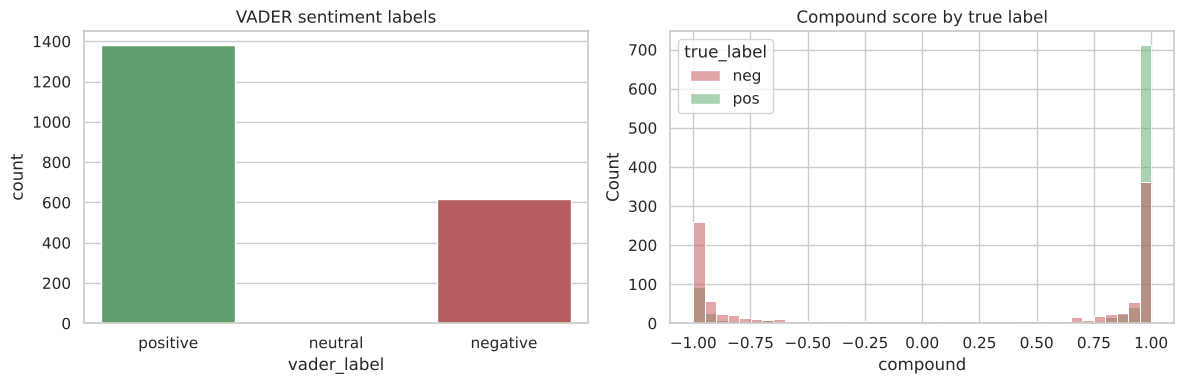

In [3]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.countplot(data=df, x="vader_label", order=["positive","neutral","negative"], palette=["#55A868","#8C8C8C","#C44E52"], ax=ax[0]); ax[0].set_title("VADER sentiment labels")
sns.histplot(data=df, x="compound", hue="true_label", bins=40, ax=ax[1], palette={"pos":"#55A868","neg":"#C44E52"}); ax[1].set_title("Compound score by true label")
plt.tight_layout(); plt.savefig("images/01_sentiment_distribution.png", dpi=150); plt.show()

## 2. How accurate is VADER? (compared to human labels)

Accuracy: 63.5%

              precision    recall  f1-score   support

         neg       0.72      0.44      0.55      1000
         pos       0.60      0.83      0.69      1000

    accuracy                           0.64      2000
   macro avg       0.66      0.64      0.62      2000
weighted avg       0.66      0.64      0.62      2000



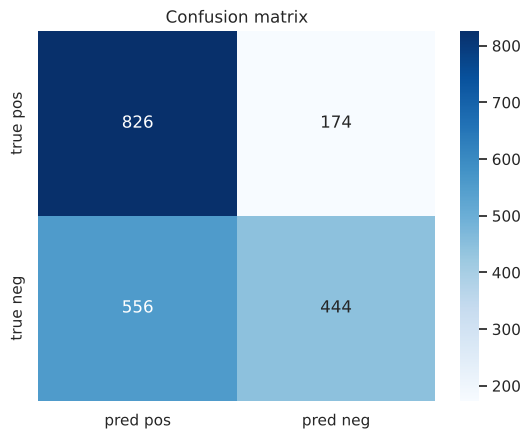

In [4]:
df['pred_binary'] = np.where(df.compound>0, "pos", "neg")
acc = (df.pred_binary==df.true_label).mean()
print(f"Accuracy: {acc:.1%}\n")
print(classification_report(df.true_label, df.pred_binary))
cm = confusion_matrix(df.true_label, df.pred_binary, labels=["pos","neg"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["pred pos","pred neg"], yticklabels=["true pos","true neg"])
plt.title("Confusion matrix"); plt.savefig("images/02_confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Which words define each sentiment?

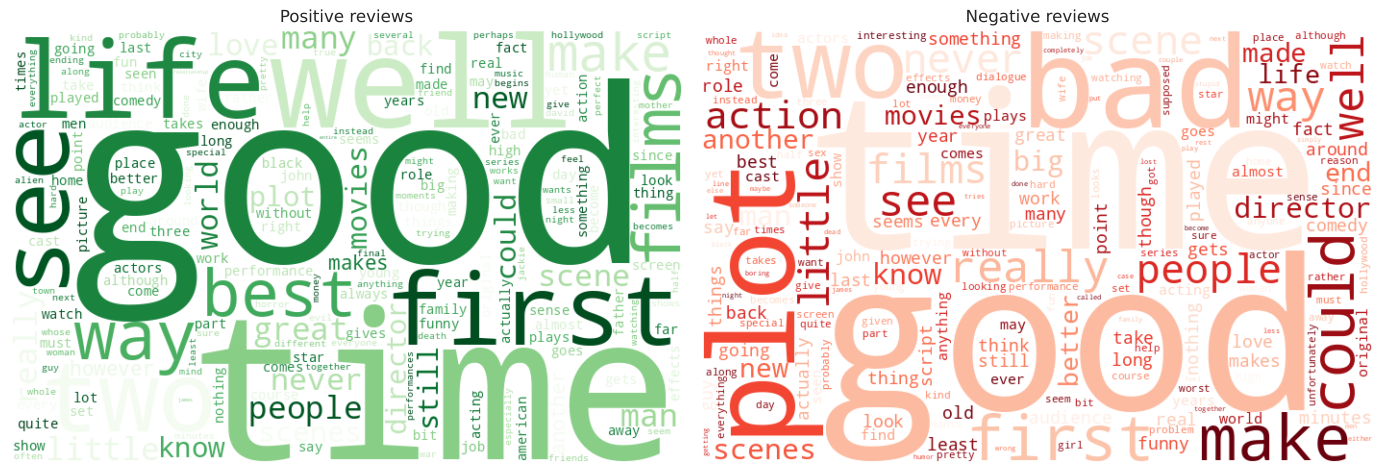

In [5]:
stop = set(stopwords.words("english")) | {"film","movie","one","even","would","also","get","much","like","story","character","characters"}
def words(texts): return [w for t in texts for w in re.findall(r"[a-z]{3,}", t.lower()) if w not in stop]
pos_words, neg_words = words(df[df.true_label=="pos"].text), words(df[df.true_label=="neg"].text)
fig, ax = plt.subplots(1,2, figsize=(14,5))
for a, w, title, col in [(ax[0],pos_words,"Positive reviews","Greens"),(ax[1],neg_words,"Negative reviews","Reds")]:
    a.imshow(WordCloud(width=700,height=450,background_color="white",colormap=col).generate_from_frequencies(Counter(w)), interpolation="bilinear")
    a.axis("off"); a.set_title(title)
plt.tight_layout(); plt.savefig("images/03_wordclouds.png", dpi=150); plt.show()

## 3b. Can a trained model do better? TF-IDF + Logistic Regression
VADER is a general-purpose lexicon. A model trained on movie reviews learns domain-specific language. I compare both on the **same held-out 25% test set**.

VADER accuracy (test set): 65.0%
Logistic Regression accuracy: 81.6%

Words pushing toward NEGATIVE: ['bad', 'worst', 'plot', 'movie', 'boring', 'supposed', 'script', 'harry', 'reason', 'stupid']
Words pushing toward POSITIVE: ['great', 'life', 'war', 'truman', 'excellent', 'perfect', 'family', 'best', 'world', 'performance']


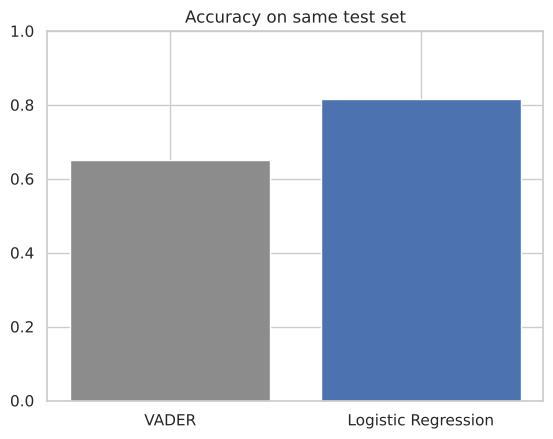

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(df.text, df.true_label, test_size=.25, random_state=42, stratify=df.true_label)
vec = TfidfVectorizer(stop_words="english", min_df=5, max_df=.8, ngram_range=(1,2))
clf = LogisticRegression(max_iter=1000).fit(vec.fit_transform(Xtr), ytr)
lr_acc = clf.score(vec.transform(Xte), yte)
vader_acc = (np.where(df.loc[Xte.index,'compound']>0,"pos","neg")==yte.values).mean()
print(f"VADER accuracy (test set): {vader_acc:.1%}\nLogistic Regression accuracy: {lr_acc:.1%}")
feat = np.array(vec.get_feature_names_out()); order_ = np.argsort(clf.coef_[0])
print("\nWords pushing toward NEGATIVE:", list(feat[order_[:10]]))
print("Words pushing toward POSITIVE:", list(feat[order_[-10:][::-1]]))
plt.bar(["VADER","Logistic Regression"], [vader_acc, lr_acc], color=["#8C8C8C","#4C72B0"]); plt.ylim(0,1); plt.title("Accuracy on same test set")
plt.savefig("images/05_model_comparison.png", dpi=150); plt.show()

## 4. Does review length relate to sentiment?

             count   mean    std    min    25%    50%    75%     max
true_label                                                          
neg         1000.0  706.0  297.0   17.0  510.0  668.0  848.0  2181.0
pos         1000.0  787.0  353.0  130.0  544.0  732.0  957.0  2678.0


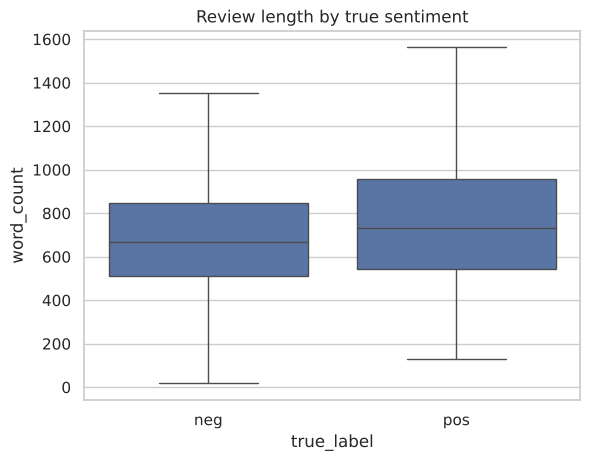

In [7]:
print(df.groupby("true_label").word_count.describe().round(0))
sns.boxplot(data=df, x="true_label", y="word_count", showfliers=False); plt.title("Review length by true sentiment")
plt.savefig("images/04_length.png", dpi=150); plt.show()

## 5. Where does VADER get it wrong?

In [8]:
wrong = df[df.pred_binary!=df.true_label]
print(f"{len(wrong)} misclassified reviews")
print("Wrong rate by true label:\n", (df.assign(wrong=df.pred_binary!=df.true_label).groupby("true_label").wrong.mean()).round(3))
for _, r in wrong.sample(2, random_state=3).iterrows():
    print(f"\nTrue: {r.true_label} | VADER compound: {r.compound:.2f}\n{r.text[:350]}...")

730 misclassified reviews
Wrong rate by true label:
 true_label
neg    0.556
pos    0.174
Name: wrong, dtype: float64

True: neg | VADER compound: 0.99
topless women talk about their lives falls into that category that i mentioned in the devil's advocate : movies that have a brilliant beginning but don't know how to end . 
it begins by introducing us to a selection of characters who all know each other . 
there is liz , who oversleeps and so is running late for her appointment , prue who is gettin...

True: neg | VADER compound: 0.99
disillusioned and trying to find the spice of life , richard ( leonardo dicaprio ) sets off for thailand . 
there he a meets crazed man by the name of daffy ( robert carlyle ) who gives him a map to a beach , a secret utopia , then commits suicide . 
richard sets off for this beach with his neighbors from this hotel , ? tienne ( guillaume canet ) a...


## Conclusions
- **VADER scored 63.5% accuracy** on 2,000 human-labeled reviews. It catches 83% of positive reviews but only **44% of negative ones**: it is biased positive.
- **Why:** reviews are long (~750 words) and mix plot summary, praise and criticism, so positive words accumulate. Sarcasm and negation hurt a lexicon approach too (two "negative" examples above scored 0.99).
- A **TF-IDF + Logistic Regression** model trained on the same domain reached **81.6%** (vs 65% for VADER on the same test set), and its top words are sensible (*worst, boring, stupid* vs *excellent, perfect, best*).
- **Business takeaway:** lexicon tools like VADER are fine for short texts (tweets, one-line reviews), but for long or domain-specific text, train a model on labeled data.
- **Limitations:** one corpus (movie reviews from the late 1990s), a simple bag-of-words model, no hyperparameter tuning. Next step: try transformer models.